# Pilot pretrained: SIFT + LightGlue và SuperPoint + LightGlue
Chạy inference, không train/fine-tune. Model tải trọng số chính thức lần đầu, cache trong Torch Hub.
Cài từ root: `uv pip install -r requirements_learned.txt`; chọn kernel `.venv` rồi Run All.
Trên Colab/Kaggle: cài file requirements bằng `%pip install -r /path/to/requirements_learned.txt`, sửa `SEQUENCE_PATH` theo nơi mount dữ liệu.
Hai phương pháp dùng cùng ảnh, 2.000 keypoints tối đa, không resize ngầm và RANSAC 3 px.
Đây là pilot cặp-frame, chưa ghép mosaic/routing; RMSE inlier không phải drift hoặc ground truth.
Nguồn: https://github.com/cvg/LightGlue (revision eb42fee2d71449efb0aa5c10549752b5d75384d8).
LightGlue: Apache-2.0; SuperPoint: giấy phép nghiên cứu phi thương mại của Magic Leap (xem README chính thức).


### 1. Đo khớp cặp frame
Chạy 3 cặp liên tiếp cho mỗi cấu hình, lưu `metrics.json` và ảnh nối điểm.

In [1]:
from pathlib import Path
import json, time, platform
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from lightglue import LightGlue, SIFT, SuperPoint
from lightglue.utils import load_image, rbd

ROOT = Path.cwd() if (Path.cwd() / "requirements.txt").exists() else Path.cwd().parent
SEQUENCE_PATH = ROOT / "data" / "phantom3-village-kfs"
NUM_PAIRS = 3
MAX_KEYPOINTS = 2000
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = ROOT / "notebooks" / "outputs" / "02_lightglue_pilot" / SEQUENCE_PATH.name
OUT.mkdir(parents=True, exist_ok=True)
files = sorted((SEQUENCE_PATH / "rgb").glob("*.jpg"), key=lambda p: float(p.stem))
if NUM_PAIRS < 1 or len(files) < NUM_PAIRS + 1:
    raise ValueError("Cần NUM_PAIRS + 1 ảnh timestamp trong SEQUENCE_PATH/rgb")
torch.manual_seed(0)
cv2.setRNGSeed(0)
print("Device:", DEVICE, "Torch:", torch.__version__, "cache:", torch.hub.get_dir())


d:\fptu\_hoc-lieu\ky4\cvprj\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cpu Torch: 2.14.1+cpu cache: C:\Users\diepq/.cache\torch\hub


sift_lightglue 0 success 869 817 0.994795560836792 0.6500725999994756


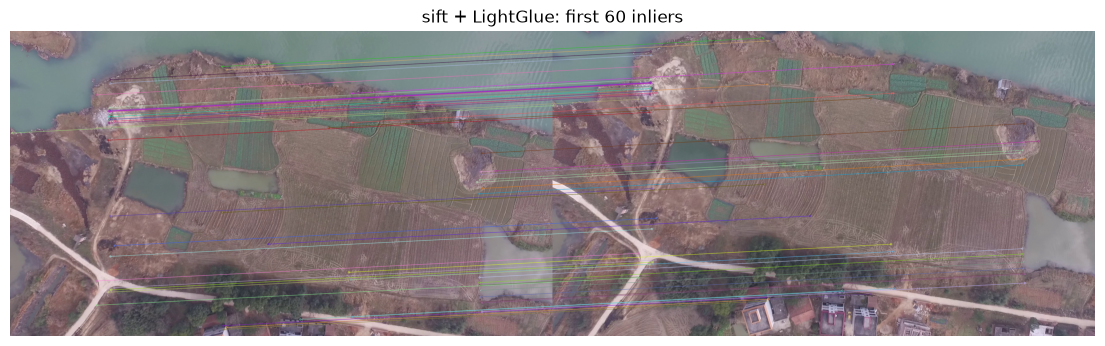

sift_lightglue 1 success 1100 1072 0.807236909866333 0.7248854999998002
sift_lightglue 2 success 1224 1210 0.4341006577014923 0.6718989999990299
superpoint_lightglue 0 success 1310 1178 1.3691164255142212 7.024175999998988


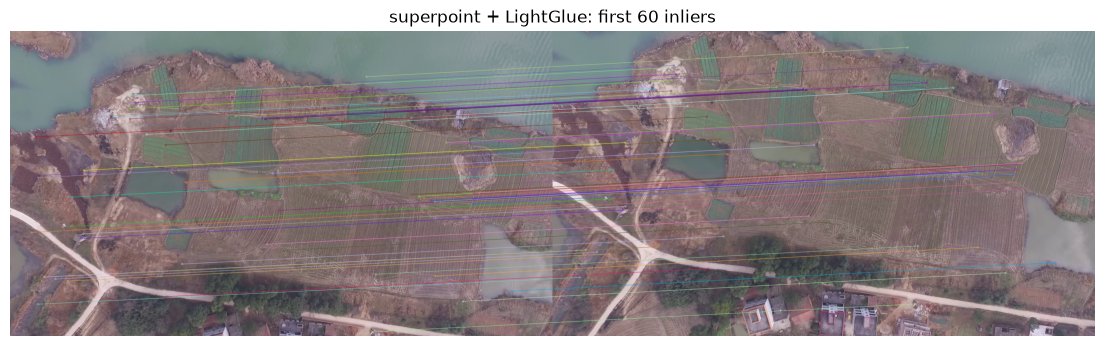

superpoint_lightglue 1 success 1523 1450 1.2577890157699585 7.021141199998965
superpoint_lightglue 2 success 1645 1612 0.9753670692443848 7.0468997999996645


In [2]:
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.inference_mode()
def match_images(extractor, matcher, image0, image1):
    f0 = extractor.extract(image0, resize=None)
    f1 = extractor.extract(image1, resize=None)
    matches = rbd(matcher({"image0": f0, "image1": f1}))["matches"]
    p0 = rbd(f0)["keypoints"][matches[:, 0]].cpu().numpy()
    p1 = rbd(f1)["keypoints"][matches[:, 1]].cpu().numpy()
    return p0, p1

records = []
for feature, extractor_type in (("sift", SIFT), ("superpoint", SuperPoint)):
    # Official SIFT wrapper includes RootSIFT, scale and orientation.
    options = {"backend": "opencv", "rootsift": True} if feature == "sift" else {}
    started = time.perf_counter()
    extractor = extractor_type(max_num_keypoints=MAX_KEYPOINTS, **options).eval().to(DEVICE)
    matcher = LightGlue(features=feature).eval().to(DEVICE)
    extractor.requires_grad_(False)
    matcher.requires_grad_(False)
    synchronize()
    setup_seconds = time.perf_counter() - started
    image0 = load_image(files[0]).to(DEVICE)
    image1 = load_image(files[1]).to(DEVICE)
    match_images(extractor, matcher, image0, image1)  # warmup on pair 0, excluded from timing
    synchronize()
    for index in range(NUM_PAIRS):
        image0 = load_image(files[index]).to(DEVICE)
        image1 = load_image(files[index + 1]).to(DEVICE)
        synchronize()
        started = time.perf_counter()
        p0, p1 = match_images(extractor, matcher, image0, image1)
        synchronize()
        match_seconds = time.perf_counter() - started
        cv2.setRNGSeed(0)
        H, mask = (cv2.findHomography(p1, p0, cv2.RANSAC, 3.0)
                   if len(p0) >= 4 else (None, None))
        good = np.zeros(len(p0), dtype=bool)
        rmse = None
        if (H is not None and np.isfinite(H).all()
                and np.linalg.matrix_rank(H) == 3 and mask is not None):
            good = mask.ravel().astype(bool)
            if good.any():
                predicted = cv2.perspectiveTransform(p1[good].reshape(-1, 1, 2), H).reshape(-1, 2)
                rmse = float(np.sqrt(np.mean(np.sum((predicted - p0[good]) ** 2, axis=1))))
        row = dict(method=feature + "_lightglue", image0=str(files[index]),
                   image1=str(files[index+1]), matches=len(p0), inliers=int(good.sum()),
                   inlier_ratio=float(good.mean()) if len(good) else 0.0,
                   rmse_px=rmse, status="success" if rmse is not None else "failed",
                   match_seconds=match_seconds, setup_seconds=setup_seconds,
                   # match_seconds = extract + match + CPU transfer; excludes IO, setup, warmup, RANSAC, rendering
                   H_current_to_previous=H.tolist() if rmse is not None else None)
        records.append(row)
        print(row["method"], index, row["status"], row["matches"], row["inliers"], rmse, match_seconds)
        if index == 0:
            a = cv2.imread(str(files[index]))
            b = cv2.imread(str(files[index+1]))
            k0 = [cv2.KeyPoint(float(x), float(y), 1) for x,y in p0]
            k1 = [cv2.KeyPoint(float(x), float(y), 1) for x,y in p1]
            links = [cv2.DMatch(int(i), int(i), 0) for i in np.flatnonzero(good)[:60]]
            view = cv2.drawMatches(a,k0,b,k1,links,None,flags=2)
            path = OUT / (feature + "_lightglue_matches.png")
            if not cv2.imwrite(str(path), view):
                raise OSError(path)
            plt.figure(figsize=(14,5))
            plt.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
            plt.title(feature + " + LightGlue: first 60 inliers")
            plt.axis("off")
            plt.show()
    del extractor, matcher
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


### 2. Dựng full bảng đồ (mosaic) ở độ phân giải gốc
Phần 1 chỉ đo **cặp frame**. Phần này nối chuỗi tuần tự rồi warp/blend thành bản đồ hoàn chỉnh cho từng cấu hình.
Khác notebook 03 (chạy 640 px), notebook này chạy **độ phân giải gốc 1920×1080, không resize** — dùng để xem độ phân giải ảnh hưởng thế nào tới bản đồ.
`build_mosaic()` dừng ngay ở cặp lỗi đầu tiên; blend cùng cách với notebook 01.

In [3]:
report = {"device": str(DEVICE), "platform": platform.platform(),
          "torch": torch.__version__, "opencv": cv2.__version__,
          "lightglue_revision": "eb42fee2d71449efb0aa5c10549752b5d75384d8",
          "max_keypoints": MAX_KEYPOINTS, "resize": None, "ransac_px": 3.0,
          "num_pairs": NUM_PAIRS, "seed": 0,
          "scope": "pair pilot only, xem mosaic_<feature>/metrics.json cho tầng bảng đồ",
          "timing": "match_seconds gồm extraction, matching, chuyển điểm về CPU; không gồm IO, setup, warmup, RANSAC, vẽ ảnh",
          "pairs": records}
with (OUT / "metrics.json").open("w", encoding="utf-8") as fh:
    json.dump(report, fh, ensure_ascii=False, indent=2, allow_nan=False)
print("Saved:", OUT / "metrics.json")

Saved: d:\fptu\_hoc-lieu\ky4\cvprj\notebooks\outputs\02_lightglue_pilot\phantom3-village-kfs\metrics.json


In [4]:
def geometry(p0, p1):
    H, mask = (cv2.findHomography(p1, p0, cv2.RANSAC, 3.0) if len(p0) >= 4 else (None, None))
    good = np.zeros(len(p0), bool)
    rmse = None
    if H is not None and mask is not None and np.isfinite(H).all() and np.linalg.matrix_rank(H) == 3:
        good = mask.ravel().astype(bool)
        if good.sum() >= 4:
            predicted = cv2.perspectiveTransform(p1[good].reshape(-1, 1, 2), H).reshape(-1, 2)
            value = float(np.sqrt(np.mean(np.sum((predicted - p0[good]) ** 2, axis=1))))
            rmse = value if np.isfinite(value) else None
    return H if rmse is not None else None, good, rmse


def canvas_and_mosaic(images, homographies, max_dim=5000):
    """Warp/blend tuần tự lên canvas chung, cùng cách làm với notebook 01."""
    corners_all = []
    for img, H in zip(images, homographies):
        h, w = img.shape[:2]
        corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], np.float32).reshape(-1, 1, 2)
        corners_all.append(cv2.perspectiveTransform(corners, H).reshape(-1, 2))
    pts = np.vstack(corners_all)
    if not np.isfinite(pts).all():
        raise ValueError("Canvas corners are not finite")
    min_x, min_y = np.floor(pts.min(axis=0)).astype(int)
    max_x, max_y = np.ceil(pts.max(axis=0)).astype(int)
    width, height = max(1, int(max_x - min_x)), max(1, int(max_y - min_y))
    scale = min(1.0, max_dim / max(width, height))
    out_w, out_h = max(1, int(width * scale)), max(1, int(height * scale))
    S = np.diag([scale, scale, 1.0])
    T = np.array([[1.0, 0.0, -min_x], [0.0, 1.0, -min_y], [0.0, 0.0, 1.0]])

    mosaic = np.zeros((out_h, out_w, 3), np.uint8)
    covered = np.zeros((out_h, out_w), bool)
    H_to_mosaic = []
    for img, H in zip(images, homographies):
        full = S @ T @ H
        H_to_mosaic.append(full)
        warped = cv2.warpPerspective(img, full, (out_w, out_h))
        ones = np.ones(img.shape[:2], np.float32)
        mask = cv2.warpPerspective(ones, full, (out_w, out_h)) > 0.5
        first = mask & ~covered
        mosaic[first] = warped[first]
        blend = mask & covered
        if blend.any():
            mosaic[blend] = (0.5 * mosaic[blend].astype(np.float32)
                             + 0.5 * warped[blend].astype(np.float32)).astype(np.uint8)
        covered |= mask
    return mosaic, H_to_mosaic, float(covered.mean()), (out_w, out_h)


def build_mosaic(matcher, method, sequence, frames, limit):
    """Nối chuỗi tuần tự tới `limit` frame; dừng ngay ở cặp lỗi đầu tiên."""
    images = [a for _, a in frames[:limit]]
    chain = []
    H_accum = [np.eye(3, dtype=np.float64)]
    for i in range(1, len(images)):
        started = time.perf_counter()
        p0, p1 = matcher(images[i - 1], images[i])
        seconds = time.perf_counter() - started
        p0, p1 = np.asarray(p0, np.float32).reshape(-1, 2), np.asarray(p1, np.float32).reshape(-1, 2)
        if p0.shape != p1.shape or not np.isfinite(p0).all() or not np.isfinite(p1).all():
            raise ValueError(f"Invalid correspondences: {method}")
        cv2.setRNGSeed(0)
        H, good, rmse = geometry(p0, p1)
        ok = H is not None
        chain.append(dict(pair=i, status="success" if ok else "failed", matches=len(p0),
                          inliers=int(good.sum()), rmse_px=rmse, match_seconds=seconds))
        if not ok:
            print(f"  {method} {sequence}: cặp {i} thất bại -> dừng chuỗi ở {len(H_accum)} frame", flush=True)
            break
        H_accum.append(H_accum[-1] @ H)
    stitched = len(H_accum)
    mosaic, H_to_mosaic, covered, size = canvas_and_mosaic(images[:stitched], H_accum)
    return mosaic, H_to_mosaic, covered, size, chain, stitched

In [5]:
MOSAIC_FRAMES = 20
mosaics = {}
for extractor_type, feature in ((SIFT, "sift"), (SuperPoint, "superpoint")):
    options = {"backend": "opencv", "rootsift": True} if feature == "sift" else {}
    extractor = extractor_type(max_num_keypoints=MAX_KEYPOINTS, **options).eval().to(DEVICE)
    matcher = LightGlue(features=feature).eval().to(DEVICE)
    extractor.requires_grad_(False)
    matcher.requires_grad_(False)

    def match_one(a, b):
        """a, b là numpy RGB uint8 (độ phân giải gốc) -> chuyển sang tensor cho LightGlue."""
        ta = torch.from_numpy(a).permute(2, 0, 1).float().to(DEVICE) / 255
        tb = torch.from_numpy(b).permute(2, 0, 1).float().to(DEVICE) / 255
        with torch.inference_mode():
            f0 = extractor.extract(ta, resize=None)
            f1 = extractor.extract(tb, resize=None)
            idx = rbd(matcher({"image0": f0, "image1": f1}))["matches"]
        return (rbd(f0)["keypoints"][idx[:, 0]].cpu().numpy(),
                rbd(f1)["keypoints"][idx[:, 1]].cpu().numpy())

    # đọc ở độ phân giải gốc, không resize
    pair_frames = []
    for f in files[:MOSAIC_FRAMES]:
        bgr = cv2.imread(str(f))
        if bgr is None:
            raise ValueError(f"Không đọc được: {f}")
        pair_frames.append((str(f), cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
    print(f"{feature}: {pair_frames[0][1].shape[1]}x{pair_frames[0][1].shape[0]} px (gốc)")

    synchronize()
    match_one(pair_frames[0][1], pair_frames[1][1])   # warmup, không tính giờ
    synchronize()
    started = time.perf_counter()
    mosaic, H_to_mosaic, covered, size, chain, stitched = build_mosaic(
        match_one, feature, SEQUENCE_PATH.name, pair_frames, len(pair_frames))
    total = time.perf_counter() - started

    folder = OUT / f"mosaic_{feature}"
    folder.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(folder / "mosaic.png"), cv2.cvtColor(mosaic, cv2.COLOR_RGB2BGR)):
        raise OSError(folder)
    with (folder / "metrics.json").open("w", encoding="utf-8") as fh:
        json.dump({"sequence": SEQUENCE_PATH.name, "method": feature + "_lightglue",
                   "resolution": "native, resize=None", "max_keypoints": MAX_KEYPOINTS,
                   "frames_requested": len(pair_frames), "frames_stitched": stitched,
                   "canvas_width": size[0], "canvas_height": size[1],
                   "canvas_covered_fraction": covered, "chain_total_seconds": total,
                   "H_to_mosaic": [m.tolist() for m in H_to_mosaic], "chain": chain},
                  fh, indent=2, ensure_ascii=False, allow_nan=False)
    mosaics[feature] = (mosaic, size, covered, stitched, total)
    print(f"mosaic {feature:11} {stitched}/{len(pair_frames)} frame | {size[0]}x{size[1]} | "
          f"phủ {covered*100:.1f}% | {total:.1f}s -> {folder.name}/mosaic.png")
    del extractor, matcher
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


sift: 1920x1080 px (gốc)
mosaic sift        20/20 frame | 1942x1851 | phủ 98.8% | 16.7s -> mosaic_sift/mosaic.png
superpoint: 1920x1080 px (gốc)
mosaic superpoint  20/20 frame | 1939x1849 | phủ 98.7% | 136.2s -> mosaic_superpoint/mosaic.png


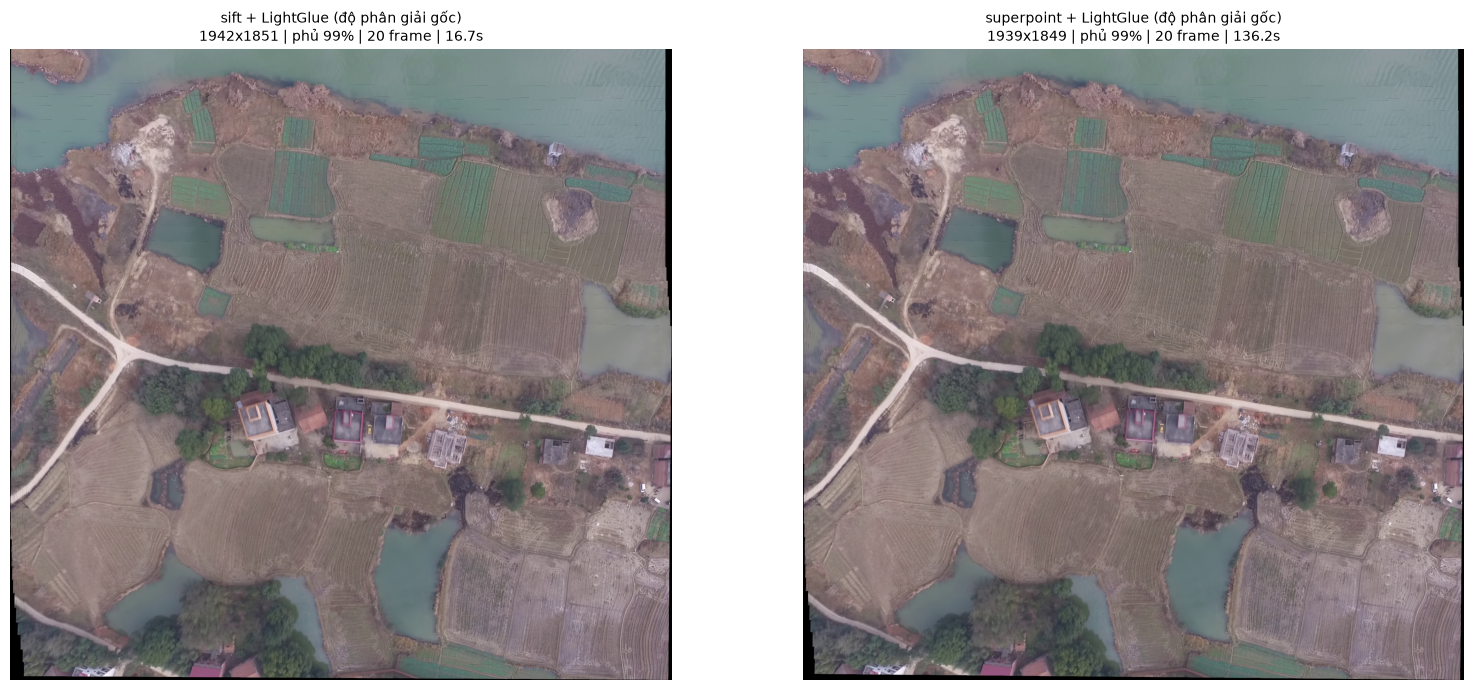

In [6]:
# Hiển thị cả 2 bản đồ để nhìn bằng mắt
fig, axes = plt.subplots(1, len(mosaics), figsize=(8 * len(mosaics), 7))
for ax, (feature, (mosaic, size, covered, stitched, total)) in zip(np.ravel(axes), mosaics.items()):
    ax.imshow(mosaic)
    ax.set_title(f"{feature} + LightGlue (độ phân giải gốc)\n"
                 f"{size[0]}x{size[1]} | phủ {covered*100:.0f}% | {stitched} frame | {total:.1f}s", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()
